In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go


In [2]:
splits = {'train': 'data/train-00000-of-00001.parquet', 'validation': 'data/validation-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
train_df = pd.read_parquet("hf://datasets/FelixCS3/statsbomb-open-data-shots/" + splits["train"])
validation_df = pd.read_parquet("hf://datasets/FelixCS3/statsbomb-open-data-shots/" + splits["validation"])
test_df = pd.read_parquet("hf://datasets/FelixCS3/statsbomb-open-data-shots/" + splits["test"])

/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
## EDA on whole dataset
dataset_df = pd.concat([train_df, validation_df, test_df], axis=0, join='outer', ignore_index=True)
print(f"Total rows: {len(dataset_df)}")
print(dataset_df.head(5))

Total rows: 88023
   match_id         competition_name season_name  match_date  \
0   3890263            1. Bundesliga   2015/2016  2015-08-15   
1   2275041  FA Women's Super League   2019/2020  2019-09-15   
2   3901191                  Ligue 1   2015/2016  2016-03-20   
3   3869219           FIFA World Cup        2022  2022-12-05   
4     69284        Women's World Cup        2019  2019-07-03   

                  team                player      x     y  distance_to_goal  \
0           Ingolstadt       Benjamin Hübner  113.8  43.2          6.977105   
1     Bristol City WFC      Abigail Harrison  101.1  25.8         23.640008   
2             OGC Nice           Rémi Walter  102.9  30.5         19.561697   
3                Japan          Takuma Asano  108.1  40.1         11.900420   
4  Netherlands Women's  Danielle van de Donk   94.0  39.4         26.006922   

   angle_to_goal  under_pressure shot_outcome_name shot_body_part_name  \
0      27.299572           False             Sav

In [31]:
dataset_df.isna().sum()

match_id               0
competition_name       0
season_name            0
match_date             0
team                   0
player                 0
x                      0
y                      0
distance_to_goal       0
angle_to_goal          0
under_pressure         0
shot_outcome_name      0
shot_body_part_name    0
shot_technique_name    0
shot_type_name         0
play_pattern_name      0
xg_statsbomb           0
is_goal                0
dtype: int64

In [4]:
print(dataset_df.describe())

print(f"Number of players: {dataset_df['player'].nunique()}")
print(f"Number of teams: {dataset_df['team'].nunique()}")
print(f"Number of competitions: {dataset_df['competition_name'].nunique()}")
dates = pd.to_datetime(dataset_df["match_date"])
print(f"Date range: {dates.min().date()} to {dates.max().date()}")

           match_id             x             y  distance_to_goal  \
count  8.802300e+04  88023.000000  88023.000000      88023.000000   
mean   2.981681e+06    103.590363     39.763707         19.180483   
std    1.553676e+06      8.795212      9.885723          8.747756   
min    7.298000e+03     30.200000      0.300000          0.400000   
25%    3.749310e+06     97.300000     32.500000         12.000417   
50%    3.825651e+06    105.000000     40.000000         18.427154   
75%    3.879869e+06    110.600000     47.000000         25.495098   
max    4.020846e+06    120.500000     80.000000         92.800862   

       angle_to_goal  xg_statsbomb       is_goal  
count   88023.000000  88023.000000  88023.000000  
mean       27.650565      0.106599      0.111221  
std        18.815851      0.149922      0.314407  
min         0.000000      0.000180      0.000000  
25%        11.999748      0.027747      0.000000  
50%        25.537434      0.054884      0.000000  
75%        40.825230 

In [5]:
## Input features will be distance_to_goal, angle_to_goal, under_pressure, shot_body_part_name, shot_technique_name, shot_type_name

cols = ["shot_body_part_name", "shot_technique_name", "shot_type_name"]
for col in cols:
    print(f"{col}: {dataset_df[col].unique().tolist()}")

shot_body_part_name: ['Left Foot', 'Right Foot', 'Head', 'Other']
shot_technique_name: ['Half Volley', 'Normal', 'Volley', 'Lob', 'Overhead Kick', 'Backheel', 'Diving Header']
shot_type_name: ['Open Play', 'Penalty', 'Free Kick', 'Corner', 'Kick Off']


Text(0, 0.5, 'Goal percentage')

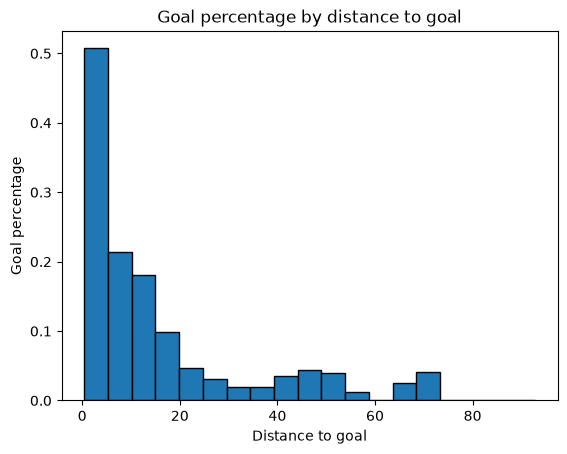

In [6]:
## plot distribution of goals by distance_to_goal

bin_edges = np.linspace(dataset_df["distance_to_goal"].min(), dataset_df["distance_to_goal"].max(), 20)

goal_percentages = []
total_goals = []
for i in range(len(bin_edges) - 1):
    left = bin_edges[i]
    right = bin_edges[i + 1]
    in_bin = dataset_df[(dataset_df["distance_to_goal"] >= left) & (dataset_df["distance_to_goal"] < right)]
    goal_percentages.append(in_bin["is_goal"].mean())
    total_goals.append(in_bin["is_goal"].sum())

plt.bar(bin_edges[:-1], goal_percentages, align="edge", width=np.diff(bin_edges), edgecolor="black")
plt.title("Goal percentage by distance to goal")
plt.xlabel("Distance to goal")
plt.ylabel("Goal percentage")

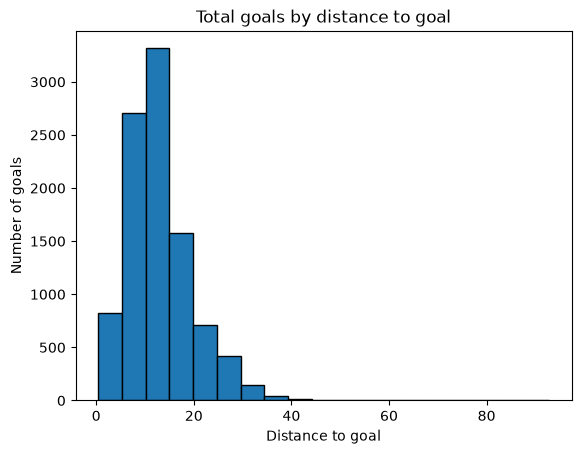

In [7]:
## Plot total goals grouped by distance
plt.bar(bin_edges[:-1], total_goals, align="edge", width=np.diff(bin_edges), edgecolor="black")
plt.title("Total goals by distance to goal")
plt.xlabel("Distance to goal")
plt.ylabel("Number of goals")

plt.show()

Text(0, 0.5, 'Goal percentage')

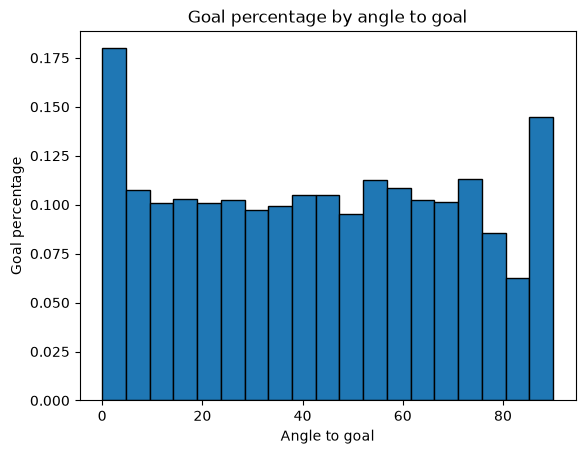

In [8]:
## plot distribution of goals by angle_to_goal

bin_edges = np.linspace(dataset_df["angle_to_goal"].min(), dataset_df["angle_to_goal"].max(), 20)

goal_percentages = []
total_goals = []
for i in range(len(bin_edges) - 1):
    left = bin_edges[i]
    right = bin_edges[i + 1]
    in_bin = dataset_df[(dataset_df["angle_to_goal"] >= left) & (dataset_df["angle_to_goal"] < right)]
    goal_percentages.append(in_bin["is_goal"].mean())
    total_goals.append(in_bin["is_goal"].sum())

plt.bar(bin_edges[:-1], goal_percentages, align="edge", width=np.diff(bin_edges), edgecolor="black")
plt.title("Goal percentage by angle to goal")
plt.xlabel("Angle to goal")
plt.ylabel("Goal percentage")

Text(0, 0.5, 'Number of goals')

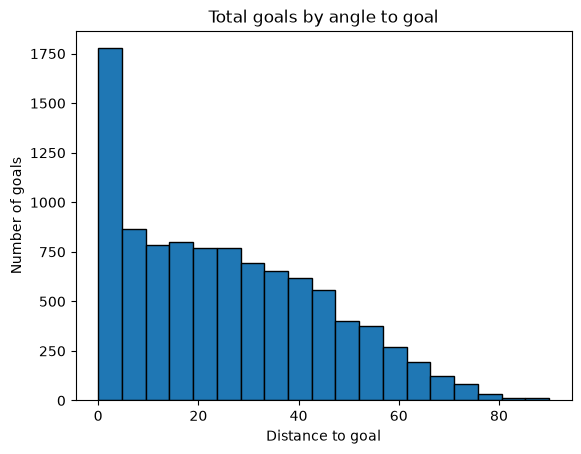

In [9]:
## Plot total goals grouped by angle
plt.bar(bin_edges[:-1], total_goals, align="edge", width=np.diff(bin_edges), edgecolor="black")
plt.title("Total goals by angle to goal")
plt.xlabel("Distance to goal")
plt.ylabel("Number of goals")

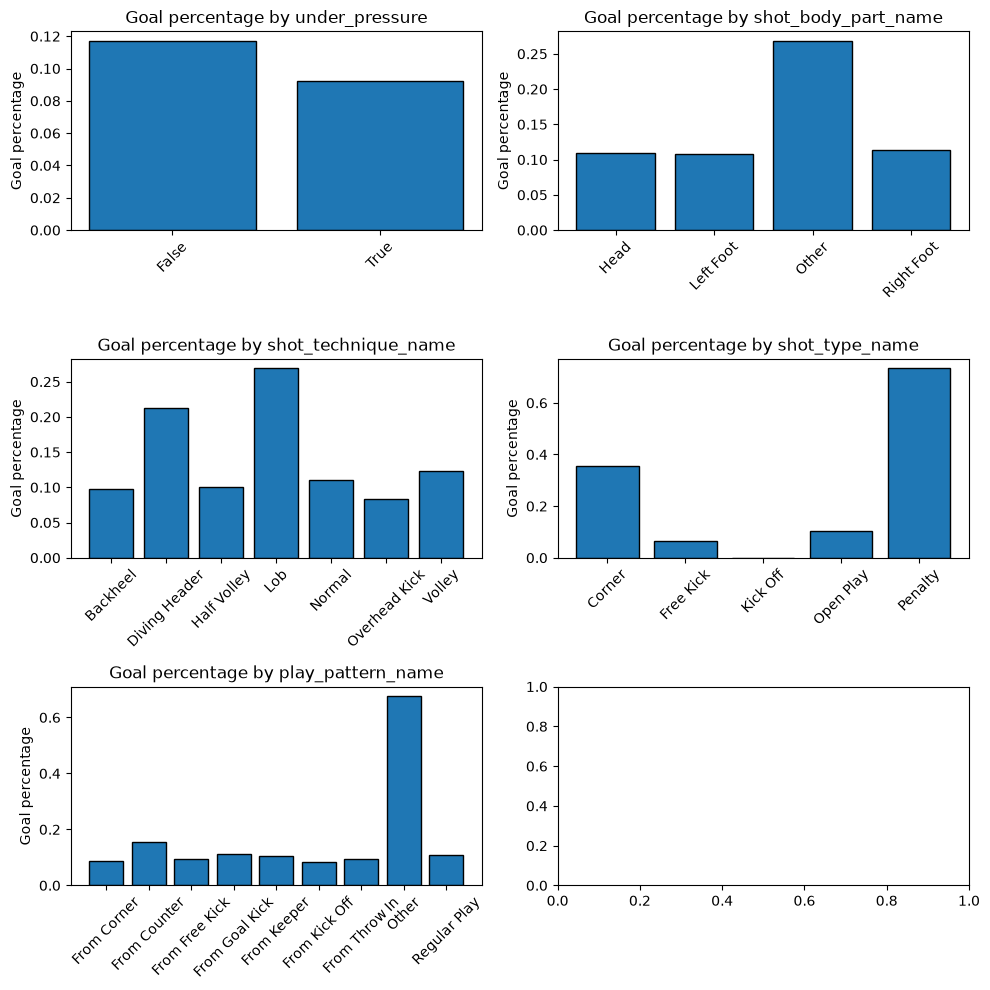

In [10]:
## View goal percentages for categorical features

cols = ["under_pressure", "shot_body_part_name", "shot_technique_name", "shot_type_name", "play_pattern_name"]

fig, axes = plt.subplots(3, 2, figsize=(10, 10))
axes = axes.flatten()

for i in range(len(cols)):
    col = cols[i]
    goal_pct = dataset_df.groupby(col)["is_goal"].mean()

    axes[i].bar(goal_pct.index.astype(str), goal_pct.values, edgecolor="black")
    axes[i].set_title(f"Goal percentage by {col}")
    axes[i].set_ylabel("Goal percentage")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

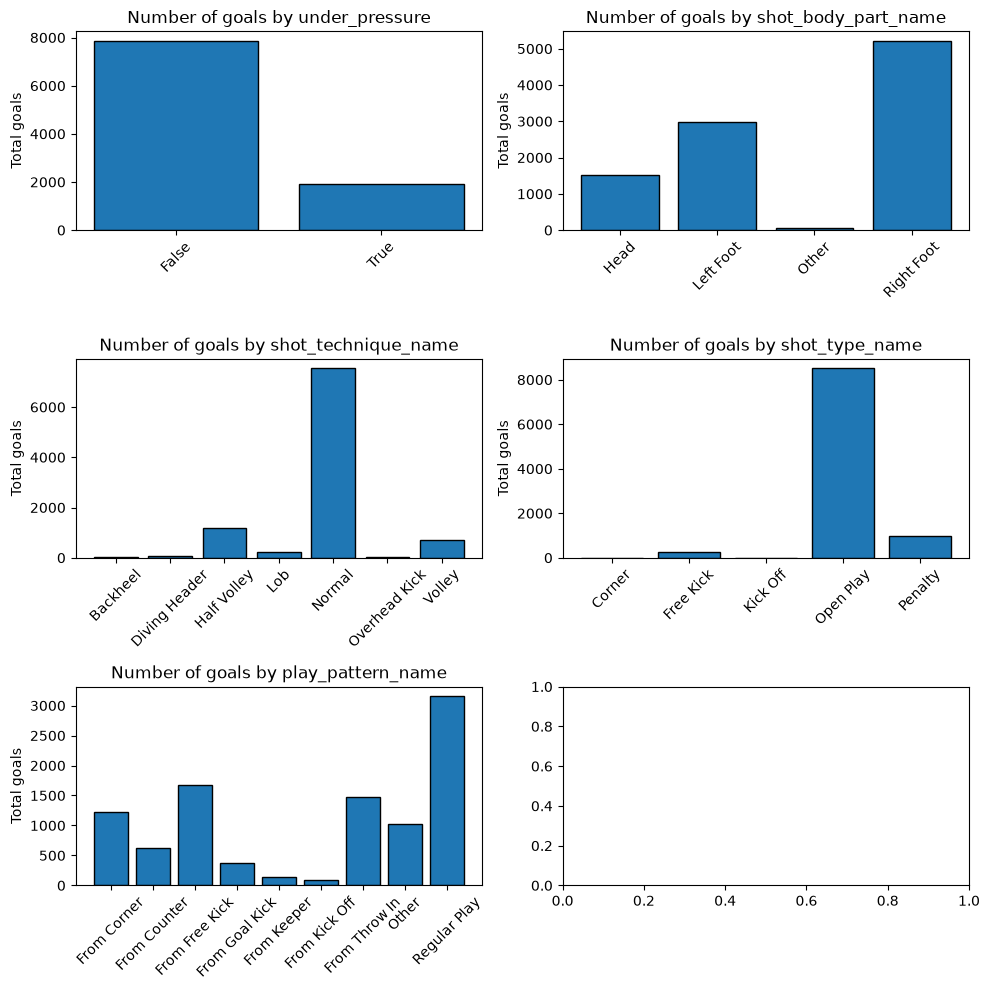

In [11]:
## View goal totals for categorical features

cols = ["under_pressure", "shot_body_part_name", "shot_technique_name", "shot_type_name", "play_pattern_name"]

fig, axes = plt.subplots(3, 2, figsize=(10, 10))
axes = axes.flatten()

for i in range(len(cols)):
    col = cols[i]
    num_goals = dataset_df.groupby(col)["is_goal"].sum()

    axes[i].bar(num_goals.index.astype(str), num_goals.values, edgecolor="black")
    axes[i].set_title(f"Number of goals by {col}")
    axes[i].set_ylabel("Total goals")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Goal percentage')

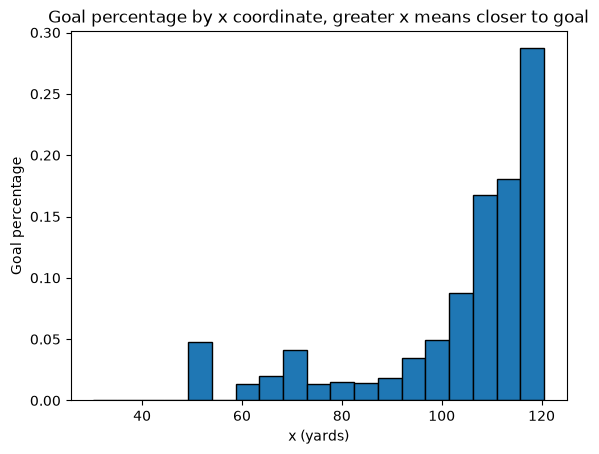

In [12]:
## Goal percentages by x, y coordinates

bin_edges = np.linspace(dataset_df["x"].min(), dataset_df["x"].max(), 20)

goal_percentages = []
total_goals = []
for i in range(len(bin_edges) - 1):
    left = bin_edges[i]
    right = bin_edges[i + 1]
    in_bin = dataset_df[(dataset_df["x"] >= left) & (dataset_df["x"] < right)]
    goal_percentages.append(in_bin["is_goal"].mean())
    total_goals.append(in_bin["is_goal"].sum())

plt.bar(bin_edges[:-1], goal_percentages, align="edge", width=np.diff(bin_edges), edgecolor="black")
plt.title("Goal percentage by x coordinate, greater x means closer to goal")
plt.xlabel("x (yards)")
plt.ylabel("Goal percentage")

Text(0, 0.5, 'Goal percentage')

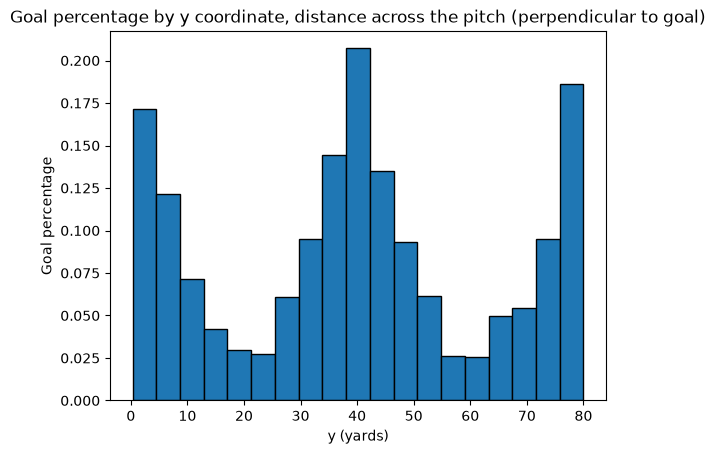

In [13]:
bin_edges = np.linspace(dataset_df["y"].min(), dataset_df["y"].max(), 20)

goal_percentages = []
total_goals = []
for i in range(len(bin_edges) - 1):
    left = bin_edges[i]
    right = bin_edges[i + 1]
    in_bin = dataset_df[(dataset_df["y"] >= left) & (dataset_df["y"] < right)]
    goal_percentages.append(in_bin["is_goal"].mean())
    total_goals.append(in_bin["is_goal"].sum())

plt.bar(bin_edges[:-1], goal_percentages, align="edge", width=np.diff(bin_edges), edgecolor="black")
plt.title("Goal percentage by y coordinate, distance across the pitch (perpendicular to goal)")
plt.xlabel("y (yards)")
plt.ylabel("Goal percentage")

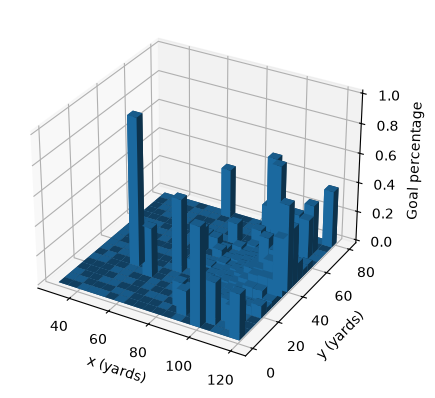

In [14]:
## Goal percentages binned by both x and y coordinates

x_edges = np.linspace(dataset_df["x"].min(), dataset_df["x"].max(), 20)
y_edges = np.linspace(dataset_df["y"].min(), dataset_df["y"].max(), 20)

xs, ys, goal_pcts, goal_totals = [], [], [], []
for i in range(len(x_edges) - 1):
    for j in range(len(y_edges) - 1):
        in_bin = dataset_df[
            (dataset_df["x"] >= x_edges[i]) & (dataset_df["x"] < x_edges[i + 1]) &
            (dataset_df["y"] >= y_edges[j]) & (dataset_df["y"] < y_edges[j + 1])
        ]
        xs.append(x_edges[i])
        ys.append(y_edges[j])
        goal_pcts.append(in_bin["is_goal"].mean())
        goal_totals.append(in_bin["is_goal"].sum())

ax = plt.figure().add_subplot(projection="3d")
ax.bar3d(xs, ys, 0, np.diff(x_edges)[0], np.diff(y_edges)[0], np.nan_to_num(goal_pcts))
ax.set_xlabel("x (yards)")
ax.set_ylabel("y (yards)")
ax.set_zlabel("Goal percentage")
plt.show()

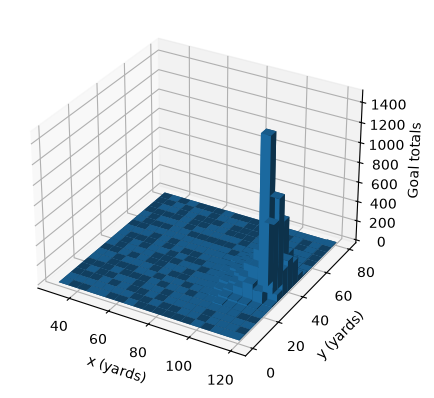

In [15]:
ax = plt.figure().add_subplot(projection="3d")
ax.bar3d(xs, ys, 0, np.diff(x_edges)[0], np.diff(y_edges)[0], np.nan_to_num(goal_totals))
ax.set_xlabel("x (yards)")
ax.set_ylabel("y (yards)")
ax.set_zlabel("Goal totals")
plt.show()